# F1 Lap-Time Prediction Model

**Goal:** estimate how quickly a driver can complete a race lap under different conditions (tyre compound and age, weather, fuel/race stage, traffic, circuit, car and driver).

**Data used (all from your three files):**
| File | What it gives the model |
|---|---|
| `cleaned_f1_laps.csv` | Lap times, driver, team, circuit, tyre compound and age, lap number, track-status code, positions |
| `weather_clean.csv` | Air and track temperature, humidity, pressure, wind, rainfall (about 1 reading per minute) |
| `track_status_clean.csv` | When yellow flags, VSC, Safety Car and red flags happened in each race |
| `combined.zip` | Starting grid (`results_*.csv`) and race-control messages (`race_control_*.csv`: DRS on/off, slippery-track warnings, rain-risk forecast). The zip's laps, weather and track-status files are the raw versions of the three CSVs above, so they are not reloaded |

**Method in one paragraph:** build a clean set of representative racing laps → attach the weather at the moment of each lap → add context features (race progress, gap to the car ahead, time since last Safety Car/VSC) → train a gradient-boosted model (LightGBM) to predict **pace relative to the race's reference lap** → multiply by a reference lap time to get seconds. Evaluation uses a strict **time-based split** (train 2021-23, validate 2024, test 2025) and compares against simple baselines. The result is a `predict_lap()` function for what-if scenarios, with a P10-P90 range.

**Why relative pace?** The same circuit's typical race lap moves by about 1 s from one season to the next (cars get faster, layouts change, up to 11 s at Singapore 2022→23). A model asked for absolute seconds spends most of its effort guessing that season-level baseline, which tyres, weather and fuel cannot explain. Splitting the problem in two is both more accurate and more honest: *conditions → relative pace* (what the model learns) and *reference lap time* (what you supply, or what the notebook estimates from the previous season).

**Important scope note:** the laps file contains **race laps only** (no qualifying or practice), so this predicts *race-pace* laps on green-flag running. It is not a qualifying-lap predictor.

In [2]:
import sys
!{sys.executable} -m pip install numpy pandas matplotlib lightgbm scikit-learn

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.5 MB/s  0:00:01


In [3]:
import sys
print(sys.executable)

C:\Users\hp\anaconda3\python.exe


In [4]:
from pathlib import Path
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")

RANDOM_SEED = 42


## 1. Setup

In [20]:
def configure_display_and_plots() -> None:
    """Set readable pandas output options and clean default matplotlib styles."""
    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", 50)

    plt.rcParams.update({
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })


import zipfile

def resolve_data_dir(
    DATA_DIR = Path(r"C:\Users\hp\Downloads\combined.zip"),
    zip_path = DATA_DIR / "combined.zip",
    extract_dir: Path = Path("./extracted_data"),
    fallback_dir: Path = Path("."),
) -> Path:
    if zip_path.exists():
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(extract_dir)
        return extract_dir
    return fallback_dir

configure_display_and_plots()

# Update preferred_dir or pass a custom path if the three CSVs live elsewhere
DATA_DIR = resolve_data_dir()

## 2. Load the data

In [21]:
laps    = pd.read_csv(r"C:\Users\hp\Downloads\cleaned_f1_laps.csv")
weather = pd.read_csv(r"C:\Users\hp\Downloads\weather_clean.csv")
track   = pd.read_csv(r"C:\Users\hp\Downloads\track_status_clean.csv")
KEY = ["year", "round"]          
print("laps   :", laps.shape,    "| races:", laps.groupby(KEY).ngroups)
print("weather:", weather.shape, "| races:", weather.groupby(KEY).ngroups)
print("track  :", track.shape,   "| races:", track.groupby(KEY).ngroups)
print("Seasons:", sorted(laps.year.unique()), "| sessions:", laps.session.unique())

laps["circuit"] = laps.location.replace({"Miami Gardens": "Miami", "Monte Carlo": "Monaco"})
print("Circuits:", laps.circuit.nunique())
laps.head(3)

laps   : (124520, 39) | races: 114
weather: (18432, 15) | races: 114
track  : (1025, 13) | races: 114
Seasons: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)] | sessions: ['Race']
Circuits: 28


,year,round,session,session_folder,event,country,location,event_date,Driver,DriverNumber,LapNumber,Stint,SpeedI1,SpeedI2,SpeedFL,SpeedST,IsPersonalBest,Compound,TyreLife,FreshTyre,Team,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,Time_s,LapTime_s,PitOutTime_s,PitInTime_s,Sector1Time_s,Sector2Time_s,Sector3Time_s,Sector1SessionTime_s,Sector2SessionTime_s,Sector3SessionTime_s,LapStartTime_s,circuit
0,2024,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2024-03-02,VER,1,1,1.0,234.0,250.0,276.0,251.0,False,SOFT,4.0,False,Red Bull Racing,2024-03-02 15:03:42.342000,12,1,False,NaN,False,False,3697.489,97.284,NaN,NaN,NaN,41.266,23.616,NaN,3673.987,3697.669,3599.911,Sakhir
1,2024,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2024-03-02,VER,1,2,1.0,232.0,248.0,276.0,287.0,True,SOFT,5.0,False,Red Bull Racing,2024-03-02 15:05:19.920000,1,1,False,NaN,False,True,3793.785,96.296,NaN,NaN,30.916,41.661,23.719,3728.426,3770.087,3793.806,3697.489,Sakhir
2,2024,1,Race,01_Race,Bahrain Grand Prix,Bahrain,Sakhir,2024-03-02,VER,1,3,1.0,231.0,243.0,276.0,290.0,False,SOFT,6.0,False,Red Bull Racing,2024-03-02 15:06:56.216000,1,1,False,NaN,False,True,3890.538,96.753,NaN,NaN,30.999,41.966,23.788,3824.805,3866.771,3890.559,3793.785,Sakhir


## 3. Put everything on one race clock

`LapStartTime_s` is session time. The weather and track-status files use **minutes since the race started** (`race_min`, `start_min`). I take the lap-1 start of each race as time zero for every driver, then check the alignment by confirming every lap flagged as Safety Car in the laps file really overlaps a Safety Car period in the track-status file.

In [22]:
t0 = laps[laps.LapNumber == 1].groupby(KEY).LapStartTime_s.min().rename("t0")
laps = laps.join(t0, on=KEY)
laps["lap_start_min"] = (laps.LapStartTime_s - laps.t0) / 60
laps["lap_end_min"]   = laps.lap_start_min + laps.LapTime_s / 60
laps["lap_mid_min"]   = (laps.lap_start_min + laps.lap_end_min) / 2

sc = track[track.status_name == "Safety Car"].assign(end=lambda d: d.start_min + d.dur_s / 60)
sc_laps = laps[laps.TrackStatus.astype(str).str.contains("4")]
hits = 0
for (y, r), g in sc_laps.groupby(KEY):
    s = sc[(sc.year == y) & (sc["round"] == r)]
    for a, b in zip(g.lap_start_min, g.lap_end_min):
        hits += ((s.start_min < b) & (s.end > a)).any()
print(f"Safety-Car laps that overlap a Safety-Car period: {hits} / {len(sc_laps)}")

Safety-Car laps that overlap a Safety-Car period: 6234 / 6234


## 4. Attach weather to each lap

For every lap I take the weather reading closest to the **middle of the lap** (same race only, max 5 minutes away). Both the race and post-race readings are used so the final laps are covered.

In [23]:
WCOLS = ["AirTemp", "TrackTemp", "Humidity", "Pressure", "WindSpeed", "WindDirection", "Rainfall"]
w = weather[weather.race_min >= 0][KEY + ["race_min"] + WCOLS].sort_values("race_min")

laps = laps.sort_values("lap_mid_min")
laps = pd.merge_asof(laps, w, left_on="lap_mid_min", right_on="race_min", by=KEY,
                     direction="nearest", tolerance=5)
laps = laps.sort_values(KEY + ["Driver", "LapNumber"]).reset_index(drop=True)
print("Laps with no weather match:", laps.AirTemp.isna().sum())
print(f"Laps run in rain: {laps.Rainfall.mean():.1%}")

Laps with no weather match: 0
Laps run in rain: 3.6%


## 5. Context features (built from the files you already have)

| Feature | Meaning | Why it matters |
|---|---|---|
| `laps_remaining`, `race_progress` | Race stage | Fuel burn: a car is roughly 0.03 s/lap quicker per kg of fuel burned, so late laps are faster |
| `gap_ahead_s` | Gap to the car in front at the **start** of the lap (capped at 10 s) | Dirty air slows cars that follow closely |
| `min_since_neutral` | Minutes since the last Safety Car/VSC/red flag ended | Restarts: cold tyres and bunched traffic |

`gap_ahead_s` uses the *previous* lap's finishing gap, so it is information the driver already has before the lap begins (no leakage from the lap being predicted).

In [24]:

laps["total_laps"] = laps.groupby(KEY)["LapNumber"].transform("max")
laps["laps_remaining"] = laps["total_laps"] - laps["LapNumber"]
laps["race_progress"] = laps["LapNumber"] / laps["total_laps"]


car_positions = (
    laps[KEY + ["LapNumber", "Position", "Time_s"]]
    .rename(columns={"Position": "pos_ahead", "Time_s": "time_ahead"})
    .drop_duplicates(subset=KEY + ["LapNumber", "pos_ahead"])
)

laps["pos_ahead"] = laps["Position"] - 1
laps = laps.merge(
    car_positions,
    on=KEY + ["LapNumber", "pos_ahead"],
    how="left",
)


raw_gap = (laps["Time_s"] - laps["time_ahead"]).where(lambda s: s >= 0)
laps = laps.sort_values(KEY + ["Driver", "LapNumber"])
laps["gap_ahead_s"] = (
    raw_gap.groupby([laps[col] for col in KEY] + [laps["Driver"]])
    .shift(1)
    .clip(lower=0, upper=10)
    .fillna(10.0)
)


MAX_MINUTES_CAP = 45.0

neutralised_periods = track[track["neutralised"]].assign(
    end_min=lambda df: df["start_min"] + df["dur_s"] / 60.0
)
neutralisation_ends = {
    group_key: np.sort(group["end_min"].to_numpy())
    for group_key, group in neutralised_periods.groupby(KEY)
}


def minutes_since_neutralisation(lap_group: pd.DataFrame) -> pd.Series:
    """Return elapsed minutes since the most recent neutralised period ended (capped at 45 min)."""
    group_key = lap_group.name if isinstance(lap_group.name, tuple) else (lap_group.name,)
    end_times = neutralisation_ends.get(group_key)

    if end_times is None or len(end_times) == 0:
        return pd.Series(MAX_MINUTES_CAP, index=lap_group.index)

    lap_starts = lap_group["lap_start_min"].to_numpy()
    # Find the latest neutralisation end time that happened at or before lap_start_min
    latest_idx = np.searchsorted(end_times, lap_starts, side="right") - 1

    elapsed = np.where(
        latest_idx >= 0,
        lap_starts - end_times[np.clip(latest_idx, 0, None)],
        MAX_MINUTES_CAP,
    )
    return pd.Series(np.clip(elapsed, 0.0, MAX_MINUTES_CAP), index=lap_group.index)


laps["min_since_neutral"] = laps.groupby(KEY, group_keys=False).apply(
    minutes_since_neutralisation
)


summary_cols = ["Driver", "LapNumber", "laps_remaining", "gap_ahead_s", "min_since_neutral"]
laps[summary_cols].describe().round(2)

,LapNumber,laps_remaining,gap_ahead_s,min_since_neutral
count,124520.00,124520.00,124520.00,124520.00
mean,30.58,30.99,4.07,35.36
std,18.35,18.42,3.53,14.86
min,1.00,0.00,0.00,0.00
25%,15.00,15.00,1.11,25.54
50%,30.00,31.00,2.56,45.00
75%,45.00,45.00,6.99,45.00
max,78.00,77.00,10.00,45.00


## 6. Extra context from `combined.zip`

The zip holds the raw per-season exports. Its laps, weather and track-status files duplicate the cleaned CSVs, and its results file has **no qualifying times** (the Q1/Q2/Q3 columns are empty), so those are not reused. Two things in it are new and are known **before or during** a lap, so they are safe inputs:

| Feature | Source | Idea |
|---|---|---|
| `grid_pos`, `team_grid_mean` | `results_*.csv` | Starting position (pit-lane start = 20) and the team's average grid slot that weekend: a one-lap-pace proxy for how strong the car and driver are *this weekend* |
| `drs_enabled` | `race_control_*.csv` | DRS is switched off when conditions are poor; latest on/off message at or before the lap |
| `slippery_recent` | `race_control_*.csv` | A "track surface slippery" warning in the last 3 laps (damp track) |
| `rain_risk_pct` | `race_control_*.csv` | The official pre-race "risk of rain" percentage (blank when none was issued) |

In [25]:
print("Current folder:", Path.cwd())
print("DATA_DIR:", DATA_DIR.resolve())
print("Looking for zip at:", (DATA_DIR / "combined.zip").resolve())
print("Exists?:", (DATA_DIR / "combined.zip").exists())

Current folder: C:\Users\hp\Downloads
DATA_DIR: C:\Users\hp\Downloads
Looking for zip at: C:\Users\hp\Downloads\combined.zip
Exists?: True


,grid_pos,team_grid_mean,drs_enabled,slippery_recent,rain_risk_pct
count,124520.00,124520.00,124520.00,124520.00,102501.00
mean,10.37,10.39,0.91,0.04,18.54
std,5.80,4.92,0.29,0.20,26.80
min,1.00,1.50,0.00,0.00,0.00
25%,5.00,6.00,1.00,0.00,0.00
50%,10.00,10.50,1.00,0.00,0.00
75%,15.00,14.50,1.00,0.00,30.00
max,20.00,20.00,1.00,1.00,100.00


In [26]:
import zipfile

zip_path = DATA_DIR / "combined.zip"


def read_zip_csvs(prefix: str) -> pd.DataFrame:
    with zipfile.ZipFile(zip_path) as zf:
        files = sorted(
            name for name in zf.namelist()
            if name.endswith(".csv") and Path(name).name.startswith(f"{prefix}_20")
        )
        return pd.concat([pd.read_csv(zf.open(f)) for f in files], ignore_index=True)


results = read_zip_csvs("results")
race_control = read_zip_csvs("race_control")

# Grid position (0 = pit lane -> 20) and team weekend average
grid_df = results[KEY + ["Abbreviation", "TeamName", "GridPosition"]].rename(
    columns={"Abbreviation": "Driver"}
)
grid_df["grid_pos"] = grid_df["GridPosition"].replace(0, 20)
grid_df["team_grid_mean"] = grid_df.groupby(KEY + ["TeamName"])["grid_pos"].transform("mean")
laps = laps.merge(grid_df[KEY + ["Driver", "grid_pos", "team_grid_mean"]], on=KEY + ["Driver"], how="left")

# Latest DRS status at or before each lap (off on laps 1-2 if no message yet)
rc_laps = race_control.dropna(subset=["Lap"]).assign(Lap=lambda d: d["Lap"].astype(int))
drs_df = (
    rc_laps[rc_laps["Category"] == "Drs"]
    .assign(drs_enabled=lambda d: d["Message"].str.contains("ENABLED").astype(int))
    .sort_values(KEY + ["Lap"])
    .drop_duplicates(KEY + ["Lap"], keep="last")[KEY + ["Lap", "drs_enabled"]]
)
laps = pd.merge_asof(
    laps.sort_values("LapNumber"),
    drs_df.sort_values("Lap"),
    left_on="LapNumber", right_on="Lap", by=KEY, direction="backward"
).drop(columns="Lap")
laps["drs_enabled"] = laps["drs_enabled"].fillna((laps["LapNumber"] > 2).astype(int))

# Slippery warning in the last 3 laps
slip_laps = {
    k: g["Lap"].to_numpy()
    for k, g in rc_laps[rc_laps["Message"].str.contains("SLIPPERY", na=False)].groupby(KEY)
}


def has_recent_slippery(group: pd.DataFrame) -> pd.Series:
    key = group.name if isinstance(group.name, tuple) else (group.name,)
    flags = np.zeros(int(group["LapNumber"].max()) + 2, dtype=int)
    if key in slip_laps:
        flags[np.clip(slip_laps[key], 0, len(flags) - 1)] = 1
    cumsum = np.cumsum(flags)
    lap_nums = group["LapNumber"].to_numpy()
    recent = (cumsum[lap_nums] - cumsum[np.clip(lap_nums - 3, 0, None)]) > 0
    return pd.Series(recent.astype(int), index=group.index)


laps = laps.sort_values(KEY + ["Driver", "LapNumber"])
laps["slippery_recent"] = laps.groupby(KEY, group_keys=False).apply(has_recent_slippery)

# Highest rain-risk percentage announced per race
rain_risk = (
    race_control[race_control["Message"].str.contains("RISK OF RAIN", na=False)]
    .assign(pct=lambda d: d["Message"].str.extract(r"IS (\d+)%")[0].astype(float))
    .groupby(KEY)["pct"].max().rename("rain_risk_pct")
)
laps = laps.join(rain_risk, on=KEY)

cols = ["grid_pos", "team_grid_mean", "drs_enabled", "slippery_recent", "rain_risk_pct"]
laps[cols].describe().round(2)

,grid_pos,team_grid_mean,drs_enabled,slippery_recent,rain_risk_pct
count,124520.00,124520.00,124520.00,124520.00,102501.00
mean,10.37,10.39,0.91,0.04,18.54
std,5.80,4.92,0.29,0.20,26.80
min,1.00,1.50,0.00,0.00,0.00
25%,5.00,6.00,1.00,0.00,0.00
50%,10.00,10.50,1.00,0.00,0.00
75%,15.00,14.50,1.00,0.00,30.00
max,20.00,20.00,1.00,1.00,100.00


## 7. Build the training set: representative racing laps

A model that has to learn "how fast can this car go" should not be asked to explain in-laps, out-laps, Safety-Car crawling or deleted laps. I keep only:

* `IsAccurate` laps that were not deleted
* **green-flag laps** (`TrackStatus == 1`, no yellow, SC or VSC anywhere on the lap)
* no pit-in / pit-out laps, and not lap 1 (standing start)
* a known tyre compound and tyre age
* laps within a sensible band of the race median (removes spins and slow-downs)

You can flip `INCLUDE_YELLOW_LAPS` to keep laps that had a local yellow.

In [28]:
INCLUDE_YELLOW_LAPS = False

ts = laps.TrackStatus.astype(str)
green = (ts == "1") if not INCLUDE_YELLOW_LAPS else ts.str.fullmatch(r"[12]+")

mask = (laps.IsAccurate & ~laps.Deleted & green
        & laps.PitInTime_s.isna() & laps.PitOutTime_s.isna()
        & (laps.LapNumber > 1)
        & laps.Compound.isin(["SOFT", "MEDIUM", "HARD", "INTERMEDIATE", "WET"])
        & laps.TyreLife.notna() & laps.AirTemp.notna())
df = laps[mask].copy()

ratio = df.LapTime_s / df.groupby(KEY).LapTime_s.transform("median")
df = df[(ratio > .85) & (ratio < 1.30)].copy()

print(f"{len(laps):,} raw laps -> {len(df):,} candidate laps ({len(df)/len(laps):.0%})")

124,520 raw laps -> 102,673 candidate laps (82%)


## 8. The race reference lap and the target

For every race I define a **reference lap time** = the median of its clean *dry-tyre, dry-weather* laps (needs at least 100 such laps). Races that were basically all wet fall back to the median reference of the same circuit in other seasons, so a wet race still shows up as "slower than the dry reference".

The model's **target** is then the pace ratio:

`pace_ratio = LapTime_s / reference_lap_s`  (1.00 = a typical dry race lap, 1.03 = 3% slower)

In [29]:
dry = df.Compound.isin(["SOFT", "MEDIUM", "HARD"]) & ~df.Rainfall
g = df[dry].groupby(KEY).LapTime_s.agg(["median", "size"])
race_info = df.groupby(KEY).agg(circuit=("circuit", "first")).join(g["median"].where(g["size"] >= 100).rename("ref_s"))

fallback = race_info.ref_s.isna()
race_info["ref_s"] = race_info.ref_s.fillna(race_info.groupby("circuit").ref_s.transform("median"))
print("Races using the circuit-fallback reference (mostly wet):", int(fallback.sum()), "| races with no reference at all:", int(race_info.ref_s.isna().sum()))

df = df.join(race_info[["ref_s"]], on=KEY)
df = df[df.ref_s.notna()].copy()
df["pace_ratio"] = df.LapTime_s / df.ref_s
print(f"Modelling laps: {len(df):,}")
display(df.groupby("year").size().to_frame("laps").T)


piv = race_info.reset_index().pivot_table(index="circuit", columns="year", values="ref_s")
drift = piv.diff(axis=1).abs().stack()
print(f"Season-to-season change in a circuit's reference lap: median {drift.median():.1f} s, 90th percentile {drift.quantile(.9):.1f} s, max {drift.max():.1f} s")

Races using the circuit-fallback reference (mostly wet): 4 | races with no reference at all: 1
Modelling laps: 101,642


year,2021,2022,2023,2024,2025
laps,18912,18068,20086,22712,21864


Season-to-season change in a circuit's reference lap: median 1.1 s, 90th percentile 2.5 s, max 11.5 s


## 9. Quick look at the data

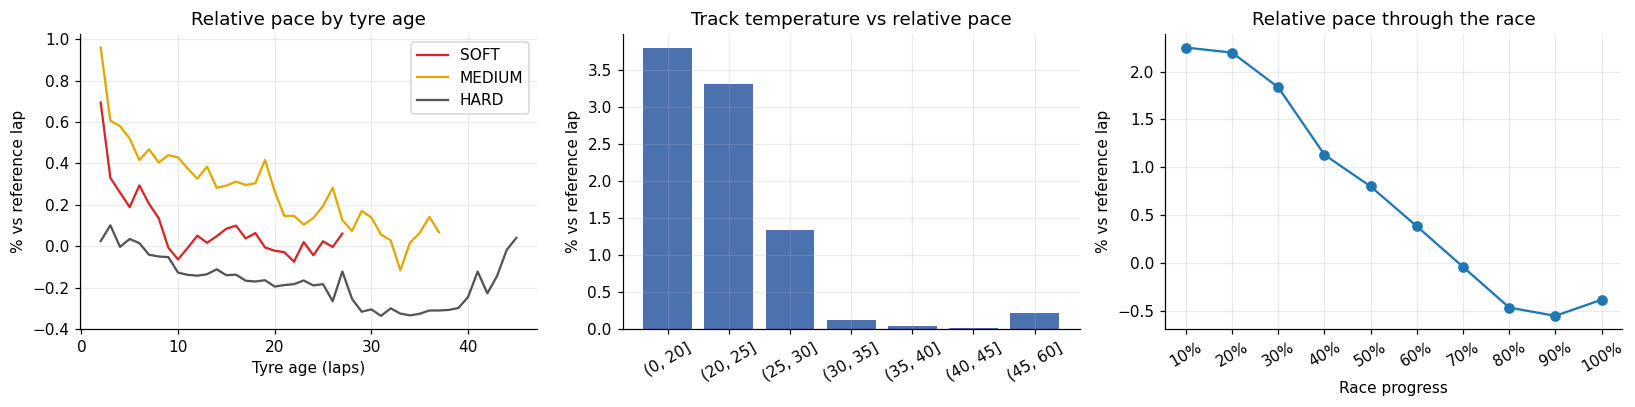

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for c, col in [("SOFT", "#d62728"), ("MEDIUM", "#e0a800"), ("HARD", "#555555")]:
    g = df[df.Compound == c].groupby("TyreLife").pace_ratio.agg(["mean", "size"]); g = g[g["size"] > 100]
    ax[0].plot(g.index, (g["mean"] - 1) * 100, label=c, color=col)
ax[0].set(title="Relative pace by tyre age", xlabel="Tyre age (laps)", ylabel="% vs reference lap"); ax[0].legend()

g = df.groupby(pd.cut(df.TrackTemp, [0, 20, 25, 30, 35, 40, 45, 60])).pace_ratio.mean()
ax[1].bar(range(len(g)), (g.values - 1) * 100, color="#4c72b0"); ax[1].set_xticks(range(len(g))); ax[1].set_xticklabels([str(i) for i in g.index], rotation=30)
ax[1].set(title="Track temperature vs relative pace", ylabel="% vs reference lap")

g = df.groupby(pd.cut(df.race_progress, np.linspace(0, 1, 11))).pace_ratio.mean()
ax[2].plot(range(len(g)), (g.values - 1) * 100, marker="o"); ax[2].set_xticks(range(len(g))); ax[2].set_xticklabels([f"{int(i.right*100)}%" for i in g.index], rotation=30)
ax[2].set(title="Relative pace through the race", xlabel="Race progress", ylabel="% vs reference lap")
plt.tight_layout(); plt.show()

## 10. Features, target and time-based split

* **Target:** `pace_ratio`
* **Not used as inputs (they are outcomes of the lap, which would leak the answer):** sector times, speed-trap speeds, `Time_s`, `IsPersonalBest`, `Position`.
* **Split by season, not randomly.** Random splits let the model see other laps from the same race, which flatters the score. Here the model is trained on 2021-23, tuned on 2024 and judged on 2025, which it has never seen.

In [31]:
CAT = ["Driver", "Team", "circuit", "Compound"]
NUM = ["year", "LapNumber", "laps_remaining", "race_progress", "TyreLife", "FreshTyre",
       "AirTemp", "TrackTemp", "Humidity", "Pressure", "WindSpeed", "WindDirection", "Rainfall",
       "gap_ahead_s", "min_since_neutral"]
EXTRA_NUM = ["grid_pos", "team_grid_mean", "drs_enabled", "slippery_recent", "rain_risk_pct"] 
BASE_FEATURES = CAT + NUM                 
NUM = NUM + EXTRA_NUM
FEATURES, TARGET = CAT + NUM, "pace_ratio"

df["FreshTyre"] = df.FreshTyre.astype(int); df["Rainfall"] = df.Rainfall.astype(int)
CATEGORIES = {c: sorted(df[c].unique()) for c in CAT}         
def prep(frame):
    X = frame[FEATURES].copy()
    for c in CAT: X[c] = pd.Categorical(X[c], categories=CATEGORIES[c])
    return X

train, valid, test = df[df.year <= 2023], df[df.year == 2024], df[df.year == 2025]
Xtr, ytr, Xva, yva, Xte, yte = prep(train), train[TARGET], prep(valid), valid[TARGET], prep(test), test[TARGET]
print(f"train {len(train):,} | valid {len(valid):,} | test {len(test):,}")

train 57,066 | valid 22,712 | test 21,864


## 11. Train the LightGBM model

In [33]:
PARAMS = dict(n_estimators=4000, learning_rate=0.03, num_leaves=63, min_child_samples=40,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              cat_smooth=20, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)

model = lgb.LGBMRegressor(objective="regression", **PARAMS)
model.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1",
          callbacks=[lgb.early_stopping(150, verbose=False)])
best_iter = model.best_iteration_
print("Best number of trees (early stopping on 2024):", best_iter)
pred_ratio = model.predict(Xte)

Best number of trees (early stopping on 2024): 209


### Do the `combined.zip` features help?
Same model, same split, with and without the extra features. Scored on 2025 with the true race reference so only the model's skill is measured.

In [34]:
def fit_eval(feats):
    def P(f):
        X = f[feats].copy()
        for c in CAT: X[c] = pd.Categorical(X[c], categories=CATEGORIES[c])
        return X
    m = lgb.LGBMRegressor(objective="regression", **PARAMS).fit(P(train), train[TARGET], eval_set=[(P(valid), valid[TARGET])],
                                                                eval_metric="l1", callbacks=[lgb.early_stopping(150, verbose=False)])
    p = m.predict(P(test))
    return {"trees": m.best_iteration_, "MAE (s), true ref": mean_absolute_error(test.LapTime_s, p * test.ref_s),
            "R2 pace ratio": r2_score(test.pace_ratio, p)}

ablation = pd.DataFrame({"Without zip features": fit_eval(BASE_FEATURES), "With zip features (used below)": fit_eval(FEATURES)}).T
ablation.round(3)

,trees,"MAE (s), true ref",R2 pace ratio
Without zip features,111.0,0.861,0.740
With zip features (used below),209.0,0.776,0.787


## 12. Test on the unseen 2025 season

Four things are compared, all scored in **seconds** on 2025 laps:

| Row | What it tells you |
|---|---|
| Circuit median (train years) | The naive "just use the circuit's usual lap time" baseline |
| Previous-season reference, no model | The reference you could know in advance, with no conditions applied |
| **Model + previous-season reference** | **The fully honest forecast**: nothing from the 2025 race is used |
| Race reference, no model | An oracle that knows each race's typical lap but ignores tyres, fuel, weather, driver |
| **Model + true race reference** | **What the model delivers when the reference pace is known** (for example from practice or qualifying) |

The gap between the two model rows is the cost of not knowing the season-level baseline in advance.

In [35]:
def metrics(y, p):
    return {"MAE (s)": mean_absolute_error(y, p), "RMSE (s)": mean_squared_error(y, p) ** .5,
            "MAPE (%)": np.mean(np.abs(y - p) / y) * 100}


ri = race_info.reset_index().sort_values(["circuit", "year", "round"])
def prior_ref(circuit, year):
    s = ri[(ri.circuit == circuit) & (ri.year < year)].ref_s
    return s.iloc[-1] if len(s) else np.nan
test = test.assign(prior_ref=[prior_ref(c, y) for c, y in zip(test.circuit, test.year)])
ok = test.prior_ref.notna().values            
t = test[ok]; y = t.LapTime_s; pr = pred_ratio[ok]

circuit_median = t.circuit.map(train.groupby("circuit").LapTime_s.median()).fillna(train.LapTime_s.median())
res = {
  "Circuit median (train years)":                        metrics(y, circuit_median),
  "Previous-season reference, no model":                 metrics(y, t.prior_ref),
  "Model + previous-season reference  (honest)":         metrics(y, pr * t.prior_ref),
  "Race reference, no model  (oracle)":                  metrics(y, t.ref_s),
  "Model + true race reference":                         metrics(y, pr * t.ref_s),
}
res = pd.DataFrame(res).T
res["R2 of pace ratio"] = [np.nan, np.nan, np.nan, np.nan, r2_score(t.pace_ratio, pr)]
print(f"{ok.sum():,} of {len(test):,} test laps (circuits with an earlier season to take a reference from)")
res.round(3)

21,864 of 21,864 test laps (circuits with an earlier season to take a reference from)


,MAE (s),RMSE (s),MAPE (%),R2 of pace ratio
Circuit median (train years),2.886,4.096,3.162,NaN
"Previous-season reference, no model",2.088,3.176,2.310,NaN
Model + previous-season reference (honest),1.682,2.271,1.895,NaN
"Race reference, no model (oracle)",1.434,2.746,1.575,NaN
Model + true race reference,0.776,1.206,0.876,0.787


### Reading the scores
* **Model vs. no model, same reference** (last two rows): the model is doing real work: it explains tyre wear, fuel, weather, traffic and driver/car differences inside the race.
* **Honest vs. true reference:** most of the remaining error in the honest row is the season-level baseline, not the model. That is a data limitation, and the fix is to bring in a reference lap from qualifying/practice (see section 19).

In [36]:
per = (t.assign(err_true_ref=pr * t.ref_s - y, err_honest=pr * t.prior_ref - y, ref_drift=t.prior_ref - t.ref_s)
         .groupby("circuit").agg(laps=("LapTime_s", "size"),
                                 MAE_true_ref=("err_true_ref", lambda s: s.abs().mean()),
                                 MAE_honest=("err_honest", lambda s: s.abs().mean()),
                                 ref_drift_s=("ref_drift", "mean"))
         .sort_values("MAE_true_ref"))
per.round(2)

,laps,MAE_true_ref,MAE_honest,ref_drift_s
circuit,,,,
Spielberg,984,0.44,0.61,0.40
Shanghai,942,0.46,3.80,3.90
São Paulo,1032,0.46,1.08,0.91
Austin,898,0.47,0.48,0.03
Yas Island,1044,0.48,0.48,0.02
Monza,878,0.52,1.36,1.30
Mexico City,1103,0.52,0.84,-0.67
Lusail,904,0.52,0.53,-0.01
Baku,796,0.55,2.78,2.95


## 13. Does it hold up on unseen races? (grouped cross-validation)

In [37]:
# Every fold holds out whole race weekends, so the model never sees any lap from the race it is scored on.
all_X, all_y = prep(df), df[TARGET]
groups = df.year.astype(str) + "-" + df.index.map(df["round"]).astype(str)
rows = []
for k, (tr, te) in enumerate(GroupKFold(5).split(all_X, all_y, groups)):
    m = lgb.LGBMRegressor(objective="regression", **{**PARAMS, "n_estimators": best_iter})
    m.fit(all_X.iloc[tr], all_y.iloc[tr])
    p = m.predict(all_X.iloc[te]); ref = df.ref_s.iloc[te]; act = df.LapTime_s.iloc[te]
    rows.append({"fold": k + 1, "MAE (s), true ref": mean_absolute_error(act, p * ref),
                 "MAE (s), flat ref": mean_absolute_error(act, ref),
                 "R2 pace ratio": r2_score(all_y.iloc[te], p)})
cv = pd.DataFrame(rows).set_index("fold"); cv.loc["mean"] = cv.mean()
cv.round(3)

,"MAE (s), true ref","MAE (s), flat ref",R2 pace ratio
fold,,,
1,0.797,1.234,0.548
2,0.708,1.450,0.790
3,1.081,1.933,0.580
4,0.877,1.726,0.767
5,0.649,1.196,0.788
mean,0.822,1.508,0.695


## 14. Diagnostics (2025, using the true race reference to isolate the model)

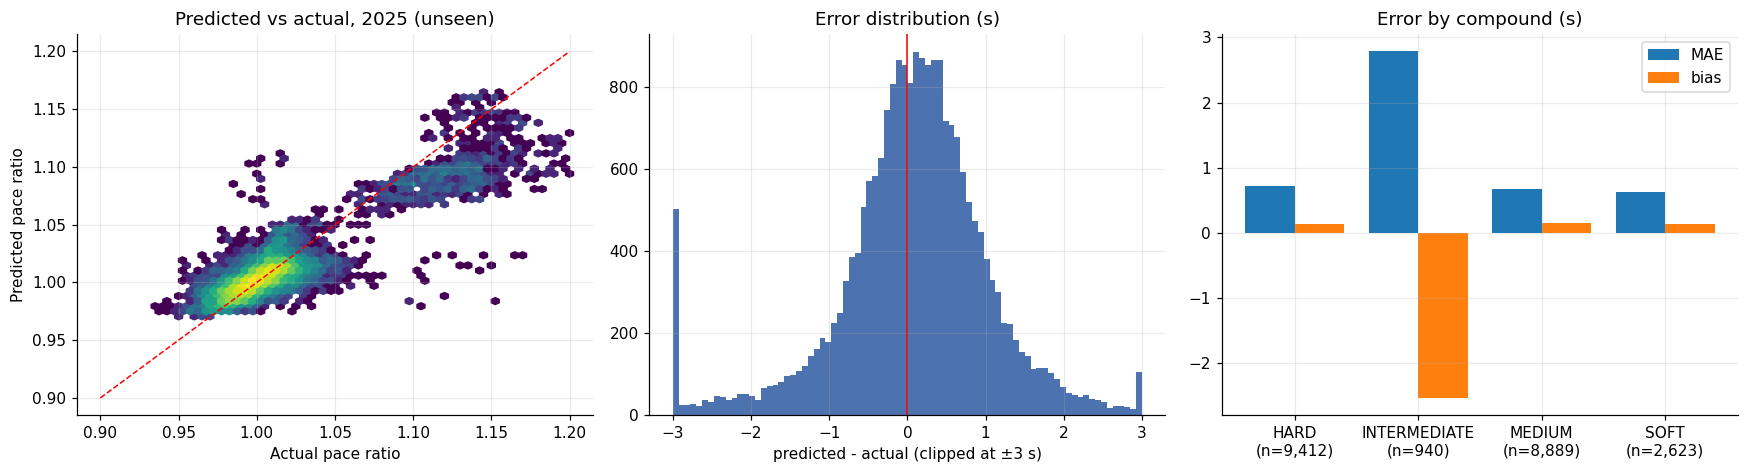

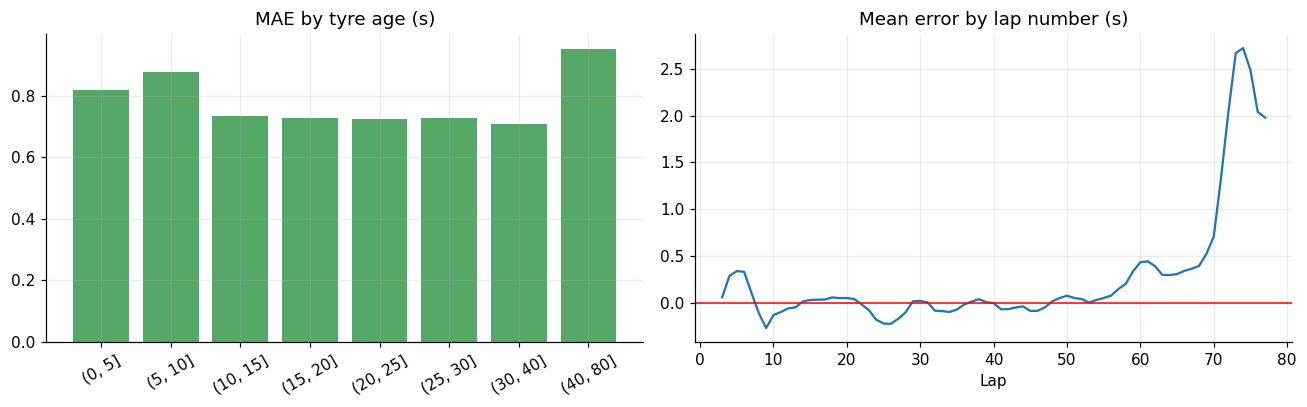

In [38]:
td = test.assign(pred_ratio=pred_ratio, err_s=(pred_ratio - test.pace_ratio) * test.ref_s)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].hexbin(td.pace_ratio, td.pred_ratio, gridsize=60, bins="log", cmap="viridis", mincnt=1, extent=(.9, 1.2, .9, 1.2))
ax[0].plot([.9, 1.2], [.9, 1.2], "r--", lw=1)
ax[0].set(xlabel="Actual pace ratio", ylabel="Predicted pace ratio", title="Predicted vs actual, 2025 (unseen)")

ax[1].hist(td.err_s.clip(-3, 3), bins=80, color="#4c72b0"); ax[1].axvline(0, color="r", lw=1)
ax[1].set(title="Error distribution (s)", xlabel="predicted - actual (clipped at ±3 s)")

g = td.groupby("Compound").err_s.agg(["mean", lambda s: s.abs().mean(), "size"]); g.columns = ["bias", "MAE", "n"]
x = np.arange(len(g)); ax[2].bar(x - .2, g.MAE, .4, label="MAE"); ax[2].bar(x + .2, g.bias, .4, label="bias")
ax[2].set_xticks(x); ax[2].set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(g.index, g.n)]); ax[2].legend(); ax[2].set(title="Error by compound (s)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
g = td.groupby(pd.cut(td.TyreLife, [0, 5, 10, 15, 20, 25, 30, 40, 80])).err_s.agg(lambda s: s.abs().mean())
ax[0].bar(range(len(g)), g.values, color="#55a868"); ax[0].set_xticks(range(len(g))); ax[0].set_xticklabels([str(i) for i in g.index], rotation=30); ax[0].set(title="MAE by tyre age (s)")
g = td.groupby("LapNumber").err_s.mean().rolling(3, center=True).mean()
ax[1].plot(g.index, g.values); ax[1].axhline(0, color="r", lw=1); ax[1].set(title="Mean error by lap number (s)", xlabel="Lap")
plt.tight_layout(); plt.show()

## 15. What drives the predictions?

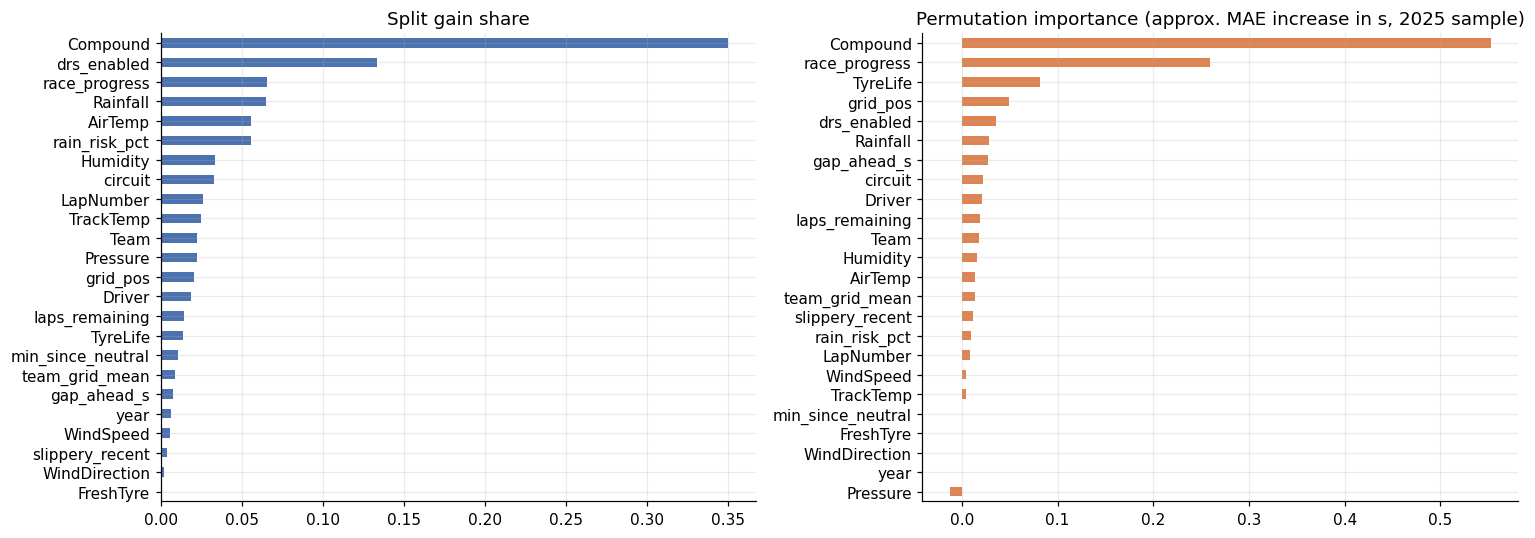

In [41]:
sample_size = min(6000, len(test))
test_sample = test.sample(sample_size, random_state=RANDOM_SEED)

# Gain-based importance from the trained LightGBM booster
gain_importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index=FEATURES,
).sort_values()

perm_result = permutation_importance(
    model,
    prep(test_sample),
    test_sample[TARGET],
    n_repeats=3,
    random_state=RANDOM_SEED,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)

perm_importance_s = pd.Series(
    perm_result.importances_mean * test_sample["ref_s"].mean(),
    index=FEATURES,
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

(gain_importance / gain_importance.sum()).plot.barh(
    ax=axes[0],
    color="#4c72b0",
)
axes[0].set_title("Split gain share")

perm_importance_s.plot.barh(
    ax=axes[1],
    color="#dd8452",
)
axes[1].set_title("Permutation importance (approx. MAE increase in s, 2025 sample)")

plt.tight_layout()
plt.show()

## 16. Prediction ranges (P10 / P50 / P90)

"How quickly *could* a driver go" is better answered with a range than a single number. Extra models are trained for the 10th and 90th percentiles of the pace ratio, then the band is calibrated on the validation season so it covers roughly 80% of laps. The P10 is a good "strong-lap" estimate; the P90 is a "things go slightly wrong" estimate (traffic, a small mistake).

In [43]:
TARGET_QUANTILES = [0.1, 0.9]
TARGET_COVERAGE = 0.80  


quantile_models = {}
for quantile in TARGET_QUANTILES:
    quantile_params = {**PARAMS, "n_estimators": best_iter}
    model_q = lgb.LGBMRegressor(
        objective="quantile",
        alpha=quantile,
        **quantile_params,
    )
    quantile_models[quantile] = model_q.fit(Xtr, ytr)

y_val_true = yva.to_numpy()
y_test_true = yte.to_numpy()

# Compute nonconformity scores on validation to calibrate interval width (CQR)
val_p10 = quantile_models[0.1].predict(Xva)
val_p90 = quantile_models[0.9].predict(Xva)
val_conformity_scores = np.maximum(val_p10 - y_val_true, y_val_true - val_p90)

finite_sample_quantile = min(
    1.0,
    TARGET_COVERAGE * (1.0 + 1.0 / len(val_conformity_scores)),
)
cqr_adjustment = float(np.quantile(val_conformity_scores, finite_sample_quantile))

# Predicting raw P10-P90 bounds on the test set and apply symmetric CQR widening
test_p10_raw = quantile_models[0.1].predict(Xte)
test_p90_raw = quantile_models[0.9].predict(Xte)

interval_variants = [
    ("raw", test_p10_raw, test_p90_raw),
    ("calibrated", test_p10_raw - cqr_adjustment, test_p90_raw + cqr_adjustment),
]

for label, lower_bound, upper_bound in interval_variants:
    inside_band = ((y_test_true >= lower_bound) & (y_test_true <= upper_bound)).mean()
    faster_than_p10 = (y_test_true < lower_bound).mean()
    slower_than_p90 = (y_test_true > upper_bound).mean()

    print(
        f"{label:>10}: {inside_band:.1%} of 2025 laps inside P10-P90 (ideal 80%) | "
        f"faster than P10: {faster_than_p10:.1%} | slower than P90: {slower_than_p90:.1%}"
    )

approx_seconds = cqr_adjustment * 90.0
print(
    f"Band widened by {cqr_adjustment:.4f} in pace-ratio terms "
    f"(about {approx_seconds:.2f} s on a 90 s lap)"
)

       raw: 63.8% of 2025 laps inside P10-P90 (ideal 80%) | faster than P10: 19.7% | slower than P90: 16.5%
calibrated: 79.4% of 2025 laps inside P10-P90 (ideal 80%) | faster than P10: 10.2% | slower than P90: 10.5%
Band widened by 0.0033 in pace-ratio terms (about 0.29 s on a 90 s lap)


## 17. Final model for scenario work
The honest test scores above come from a model that never saw 2025. For actual predictions I refit on **all** seasons (2021-25) with the same settings.

`predict_lap()` needs a **reference lap time** to turn pace ratio into seconds. If you do not give one it uses the most recent race at that circuit, which is the "honest" option from section 12. If you have a better number (a qualifying or practice long-run pace for the weekend), pass it as `reference_lap_s`.

In [44]:
full_features = prep(df)
full_target = df[TARGET]

final_trees = int(best_iter * 1.1)
final_model = lgb.LGBMRegressor(
    objective="regression",
    **{**PARAMS, "n_estimators": final_trees},
).fit(full_features, full_target)

final_quantile_models = {
    quantile: lgb.LGBMRegressor(
        objective="quantile",
        alpha=quantile,
        **{**PARAMS, "n_estimators": best_iter},
    ).fit(full_features, full_target)
    for quantile in QUANTILES
}

In [45]:
weather_and_race_cols = [
    "AirTemp",
    "TrackTemp",
    "Humidity",
    "Pressure",
    "WindSpeed",
    "WindDirection",
    "total_laps",
]

recent_seasons = df[df["year"] >= 2023]
circuit_defaults = recent_seasons.groupby("circuit")[weather_and_race_cols].median()

latest_team_by_driver = (
    df.sort_values(["year", "round"])
    .groupby("Driver")["Team"]
    .last()
)
latest_ref_by_circuit = ri.groupby("circuit")["ref_s"].last()

latest_season = df[df["year"] == df["year"].max()]
grid_by_driver = latest_season.groupby("Driver")["grid_pos"].mean()
grid_by_team = latest_season.groupby("Team")["team_grid_mean"].mean()
typical_rain_risk = float(df.groupby(KEY)["rain_risk_pct"].first().median())

In [46]:
def format_lap_time(seconds: float) -> str:
    """Format seconds as m:ss.sss (for example, 83.45 -> '1:23.450')."""
    minutes, remainder_s = divmod(seconds, 60)
    return f"{int(minutes)}:{remainder_s:06.3f}"


def predict_lap(
    driver: str,
    circuit: str,
    compound: str,
    tyre_life: int,
    lap_number: int,
    team: str | None = None,
    year: int = 2025,
    fresh_tyre: bool = False,
    rain: bool = False,
    gap_ahead_s: float = 10.0,
    min_since_neutral: float = 45.0,
    total_laps: int | None = None,
    reference_lap_s: float | None = None,
    grid_pos: float | None = None,
    drs_enabled: bool | None = None,
    **weather_overrides,
) -> dict[str, float]:
    """Predict lap time and calibrated P10-P90 bounds (in seconds) for a lap scenario."""
    defaults = circuit_defaults.loc[circuit].to_dict()
    defaults.update(weather_overrides)

    race_total_laps = total_laps if total_laps is not None else defaults["total_laps"]
    ref_lap_s = reference_lap_s if reference_lap_s is not None else latest_ref_by_circuit[circuit]
    driver_team = team if team is not None else latest_team_by_driver[driver]
    default_grid = grid_by_driver.get(driver, 10.5)
    default_drs = int(not rain)

    scenario_row = {
        "Driver": driver,
        "Team": driver_team,
        "circuit": circuit,
        "Compound": compound,
        "year": year,
        "LapNumber": lap_number,
        "laps_remaining": race_total_laps - lap_number,
        "race_progress": lap_number / race_total_laps,
        "TyreLife": tyre_life,
        "FreshTyre": int(fresh_tyre),
        "AirTemp": defaults["AirTemp"],
        "TrackTemp": defaults["TrackTemp"],
        "Humidity": defaults["Humidity"],
        "Pressure": defaults["Pressure"],
        "WindSpeed": defaults["WindSpeed"],
        "WindDirection": defaults["WindDirection"],
        "Rainfall": int(rain),
        "gap_ahead_s": gap_ahead_s,
        "min_since_neutral": min_since_neutral,
        "grid_pos": grid_pos if grid_pos is not None else default_grid,
        "team_grid_mean": grid_by_team.get(driver_team, 10.5),
        "drs_enabled": int(drs_enabled) if drs_enabled is not None else default_drs,
        "slippery_recent": int(rain),
        "rain_risk_pct": 80.0 if rain else typical_rain_risk,
    }

    prepared_row = prep(pd.DataFrame([scenario_row]))
    pred_ratio = float(final_model.predict(prepared_row)[0])
    p10_ratio = float(final_quantile_models[0.1].predict(prepared_row)[0]) - CQR_ADJ
    p90_ratio = float(final_quantile_models[0.9].predict(prepared_row)[0]) + CQR_ADJ

    return {
        "predicted_s": pred_ratio * ref_lap_s,
        "p10_s": p10_ratio * ref_lap_s,
        "p90_s": p90_ratio * ref_lap_s,
    }


sample_pred = predict_lap("VER", "Silverstone", "MEDIUM", tyre_life=8, lap_number=20)
print(
    "VER, Silverstone, MEDIUM (8 laps old), lap 20, clear air:",
    format_lap_time(sample_pred["predicted_s"]),
    f"(range {format_lap_time(sample_pred['p10_s'])} - {format_lap_time(sample_pred['p90_s'])})",
)
print("Reference lap used:", format_lap_time(latest_ref_by_circuit["Silverstone"]))

VER, Silverstone, MEDIUM (8 laps old), lap 20, clear air: 1:31.346 (range 1:30.352 - 1:32.187)
Reference lap used: 1:31.669


## 18. What-if scenarios
Pick any circuit and driver by editing the first line. All curves come straight from `predict_lap()`. They show *relative* effects (tyre wear, temperature, traffic), which are the most reliable part of the model.

In [47]:
DRIVER_NAME = "VER"
CIRCUIT_NAME = "Silverstone"

COMPOUND_COLORS = {
    "SOFT": "#d62728",
    "MEDIUM": "#e0a800",
    "HARD": "#555555",
}
CLEAN_AIR_COLOR = "#4c72b0"

# Pure Tyre-Age Effect (Fixed Lap Number)

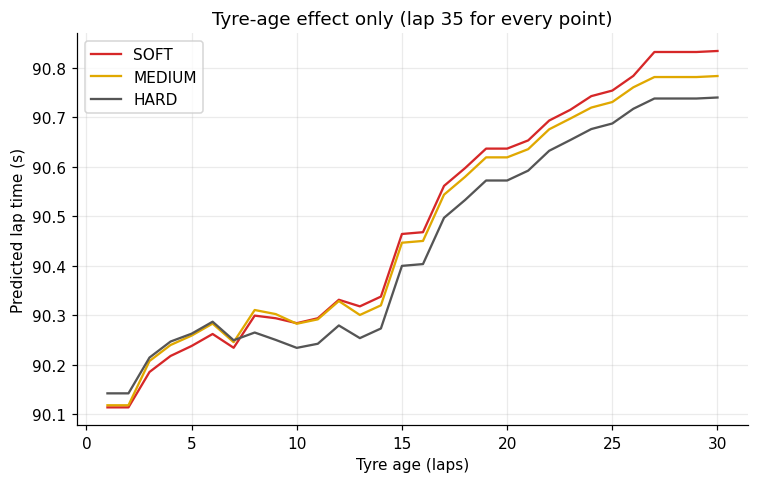

In [48]:

tyre_ages = list(range(1, 31))

fig, ax = plt.subplots(figsize=(7, 4.5))

for compound, color in COMPOUND_COLORS.items():
    lap_times = [
        predict_lap(DRIVER_NAME, CIRCUIT_NAME, compound, age, lap_number=35)["predicted_s"]
        for age in tyre_ages
    ]
    ax.plot(tyre_ages, lap_times, label=compound, color=color)

ax.set_title("Tyre-age effect only (lap 35 for every point)")
ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Predicted lap time (s)")
ax.legend()

plt.tight_layout()
plt.show()

# Realistic Stint (Tyre Age + Fuel Burn)

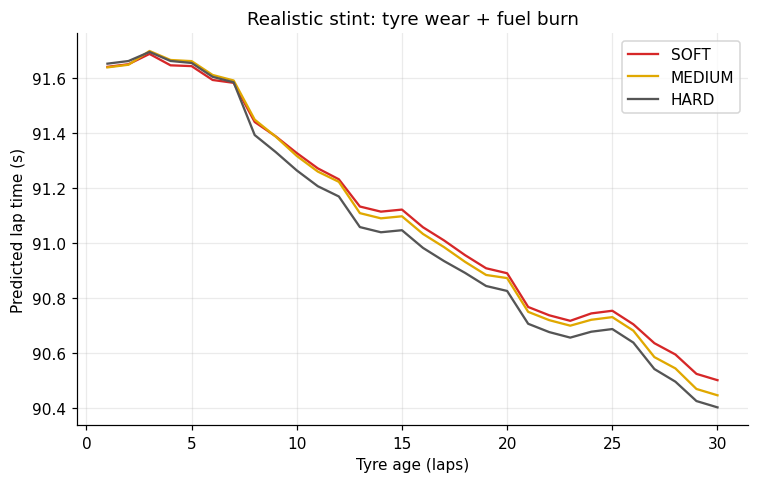

In [49]:
tyre_ages = list(range(1, 31))

fig, ax = plt.subplots(figsize=(7, 4.5))

for compound, color in COMPOUND_COLORS.items():
    stint_times = [
        predict_lap(DRIVER_NAME, CIRCUIT_NAME, compound, age, lap_number=10 + age)["predicted_s"]
        for age in tyre_ages
    ]
    ax.plot(tyre_ages, stint_times, label=compound, color=color)

ax.set_title("Realistic stint: tyre wear + fuel burn")
ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Predicted lap time (s)")
ax.legend()

plt.tight_layout()
plt.show()

## Track Temperature Effects

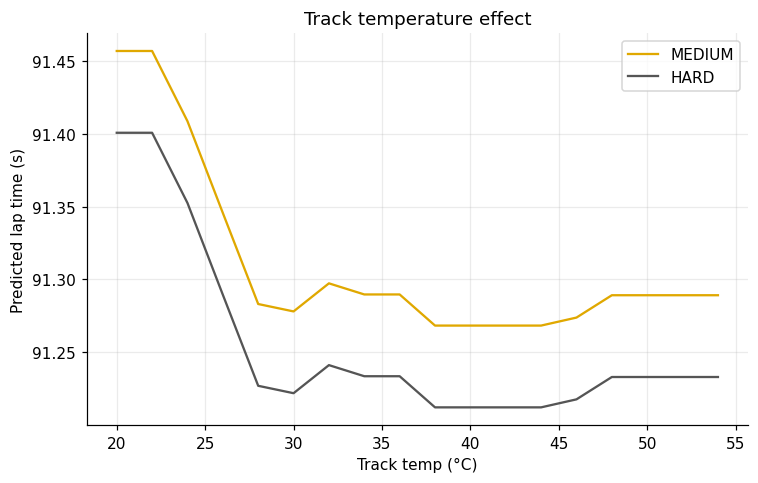

In [50]:
track_temps_c = np.arange(20, 56, 2)

fig, ax = plt.subplots(figsize=(7, 4.5))

for compound in ["MEDIUM", "HARD"]:
    temp_times = [
        predict_lap(
            DRIVER_NAME,
            CIRCUIT_NAME,
            compound,
            tyre_life=8,
            lap_number=20,
            TrackTemp=temp,
        )["predicted_s"]
        for temp in track_temps_c
    ]
    ax.plot(track_temps_c, temp_times, label=compound, color=COMPOUND_COLORS[compound])

ax.set_title("Track temperature effect")
ax.set_xlabel("Track temp (°C)")
ax.set_ylabel("Predicted lap time (s)")
ax.legend()

plt.tight_layout()
plt.show()

## Dirty Air Effects (Gap to Car Ahead)

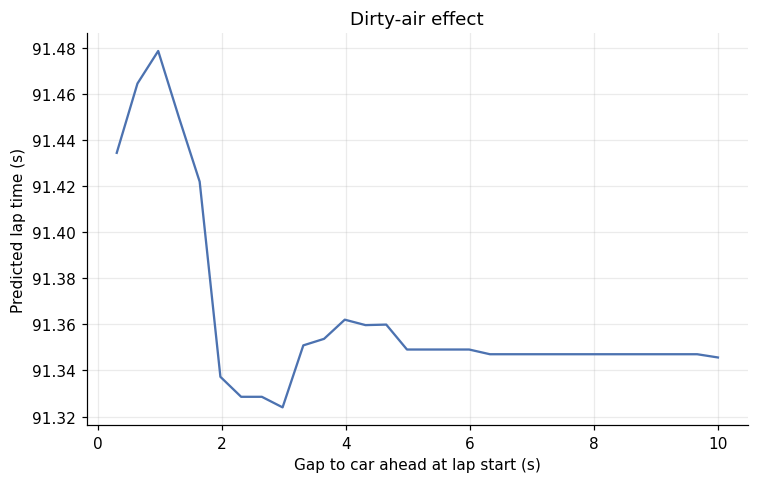

In [51]:
gaps_ahead_s = np.linspace(0.3, 10.0, 30)

fig, ax = plt.subplots(figsize=(7, 4.5))

traffic_times = [
    predict_lap(
        DRIVER_NAME,
        CIRCUIT_NAME,
        "MEDIUM",
        tyre_life=8,
        lap_number=20,
        gap_ahead_s=gap,
    )["predicted_s"]
    for gap in gaps_ahead_s
]
ax.plot(gaps_ahead_s, traffic_times, color=CLEAN_AIR_COLOR)

ax.set_title("Dirty-air effect")
ax.set_xlabel("Gap to car ahead at lap start (s)")
ax.set_ylabel("Predicted lap time (s)")

plt.tight_layout()
plt.show()

**How to read these:** tyre age and lap number move together in real races (older tyres = later in the race = lighter car), so the data cannot cleanly separate wear from fuel burn. The left chart holds the lap fixed; the right chart is what actually happens in a stint, where fuel burn can outweigh wear on low-degradation circuits. The temperature effect is small because differences *between* races are absorbed into the reference lap, leaving only the effect of warming or cooling within a race.

In [53]:
# Comparing all 2025 drivers under identical baseline conditions (8-lap-old MEDIUM, lap 20)
grid_2025_drivers = sorted(df.loc[df["year"] == 2025, "Driver"].unique())

comparison_rows = []
for driver_code in grid_2025_drivers:
    lap_prediction = predict_lap(
        driver=driver_code,
        circuit=CIRCUIT_NAME,
        compound="MEDIUM",
        tyre_life=8,
        lap_number=20,
    )
    comparison_rows.append({
        "Driver": driver_code,
        "Team": latest_team_by_driver[driver_code],
        **lap_prediction,
    })

driver_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("predicted_s")
    .reset_index(drop=True)
)
driver_comparison["gap_to_fastest_s"] = (
    driver_comparison["predicted_s"] - driver_comparison["predicted_s"].min()
)

display_cols = [
    "Driver",
    "Team",
    "predicted_s",
    "p10_s",
    "p90_s",
    "gap_to_fastest_s",
]
driver_comparison[display_cols].round(3)

,Driver,Team,predicted_s,p10_s,p90_s,gap_to_fastest_s
0,VER,Red Bull Racing,91.346,90.352,92.187,0.000
1,PIA,McLaren,91.419,90.383,92.244,0.073
2,NOR,McLaren,91.447,90.357,92.222,0.102
3,LEC,Ferrari,91.589,90.629,92.317,0.244
4,RUS,Mercedes,91.718,90.730,92.357,0.372
5,HAM,Ferrari,91.805,90.669,92.510,0.459
6,ANT,Mercedes,92.010,90.944,92.629,0.664
7,TSU,Red Bull Racing,92.365,91.145,93.318,1.019
8,HAD,Racing Bulls,92.545,91.296,92.907,1.199
9,SAI,Williams,92.621,91.222,92.956,1.275


In [54]:
# Comparing a baseline dry lap against a wet intermediate-tyre scenario
dry_pred = predict_lap(
    driver=DRIVER_NAME,
    circuit=CIRCUIT_NAME,
    compound="MEDIUM",
    tyre_life=8,
    lap_number=20,
)
wet_pred = predict_lap(
    driver=DRIVER_NAME,
    circuit=CIRCUIT_NAME,
    compound="INTERMEDIATE",
    tyre_life=8,
    lap_number=20,
    rain=True,
    AirTemp=14,
    TrackTemp=17,
    Humidity=85,
)

dry_lap_s = dry_pred["predicted_s"]
wet_lap_s = wet_pred["predicted_s"]
wet_delta_s = wet_lap_s - dry_lap_s

print(
    f"Dry MEDIUM: {format_lap_time(dry_lap_s)} | "
    f"Wet INTERMEDIATE: {format_lap_time(wet_lap_s)} | "
    f"difference {wet_delta_s:+.1f} s"
)

# Checking wet-weather sample size in the training dataset
rain_laps = int(df["Rainfall"].sum())
rain_share = df["Rainfall"].mean()
wet_compound_laps = int(df["Compound"].isin(["INTERMEDIATE", "WET"]).sum())

print(
    f"Rain laps in training data: {rain_laps:,} ({rain_share:.1%}) | "
    f"wet/intermediate-tyre laps: {wet_compound_laps:,}"
)

Dry MEDIUM: 1:31.346 | Wet INTERMEDIATE: 1:42.385 | difference +11.0 s
Rain laps in training data: 2,763 (2.7%) | wet/intermediate-tyre laps: 4,526


baseline, and it also lets you predict one-lap qualifying pace, which this race-only dataset cannot do.
2. **Circuit attributes:** track length, number of corners, % full throttle, altitude, surface abrasiveness. This lets the model handle new or modified circuits and learn *why* circuits differ.
3. **Pirelli compound grade per event** (C1-C5). "HARD" at Monaco and "HARD" at Silverstone are different tyres.
4. **Car/engine performance by round** (for example a rolling team pace index) to capture upgrades.
5. **Stint and fuel strategy** (starting fuel estimate, planned stops) to replace the `laps_remaining` proxy.
6. **DRS-train information** (cars